# BPD Voltage Metrics

Examines two key metrics of the BPD (Balanced Photodetector) signal across the phase delay scan:

1. **Peak-to-Peak (P2P) voltage** — demonstrates and fixes the noise-floor artifact in the naive P2P calculation
2. **Integral of voltage** — integrate |EO signal| over the delay scan, with tunable cutoffs to isolate the primary signal

Same metrics are then applied to the ICT waveform.

In [1]:
import os
#import matplotlib; matplotlib.use('Agg')
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')

os.makedirs('Results', exist_ok=True)

RF_Hz           = 81.25e6
T_LASER_NS      = 1e9 / RF_Hz
mV              = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FLANK_END_NS    = 100.0
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25
ICT_BL_PRE      = slice(None, 800)
ICT_BL_POST     = slice(1300, None)

SCANS = [
    {'label': '0.25 nC', 'Q': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC',  'Q': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC',    'Q': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC',    'Q': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC',    'Q': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC',    'Q': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(SCANS)))
print('Setup done. CWD:', os.getcwd())

Setup done. CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26


In [2]:
# ── Pipeline functions ─────────────────────────────────────────────────────────
def _period_fill(t_ns, s0, s1):
    dt  = (t_ns[-1]-t_ns[0])/(len(t_ns)-1); T=T_LASER_NS/dt
    i0  = int(round(s0/dt)); i1=int(round(s1/dt))
    idx = np.arange(i0,i1)
    nl  = np.ceil((idx+1-i0)/T).astype(int); nr=np.ceil((i1-idx)/T).astype(int)
    return i0,i1,np.round(idx-nl*T).astype(int),np.round(idx+nr*T).astype(int)

def fft_lp(res, dt_ns):
    n=res.shape[1]; freqs=np.fft.rfftfreq(n,d=dt_ns)
    filt=np.exp(-0.5*(freqs/FFT_SIGMA_GHZ)**(2*FFT_ORDER))
    return np.fft.irfft(np.fft.rfft(res,axis=1)*filt,n=n,axis=1)

def load_bpd(path):
    """Returns (delay_ps, signed_amplitude, residual, t_ns, raw_traces, probe_time_idx)."""
    d=np.load(path); t_ns=1e9*d['x'][0,:]
    phase=d['phase']; delay_ps=(phase-phase[0])/RF_Hz/360*1e12
    dt=(t_ns[-1]-t_ns[0])/(len(t_ns)-1)
    traces=d['BPDwf'].mean(axis=1)
    i0,i1,sl,sr=_period_fill(t_ns,SIGNAL_START_NS,SIGNAL_END_NS)
    bl=traces.copy(); bl[:,i0:i1]=0.5*(traces[:,sl]+traces[:,sr])
    res=fft_lp(traces-bl,dt)
    tp=res.var(axis=0).argmax()
    win=slice(max(0,tp-PROBE_HALF_WIN),min(res.shape[1],tp+PROBE_HALF_WIN))
    sig=res[:,win].mean(axis=1)
    return delay_ps, sig, res, t_ns, traces, tp

def load_ict(path):
    d=np.load(path); ict=d['ictwf'].mean(axis=1)
    bl=np.concatenate([ict[:,ICT_BL_PRE],ict[:,ICT_BL_POST]],axis=1).mean(axis=1)
    ict_c=ict-bl[:,np.newaxis]
    return ict_c  # (steps, 2502), baseline-corrected

# Pre-load all scans
all_data = []
for s in SCANS:
    dp, sig, res, t_ns, traces, tp = load_bpd(s['path'])
    ict_c = load_ict(s['path'])
    all_data.append({'label':s['label'],'Q':s['Q'],
                     'delay_ps':dp,'sig':sig,'res':res,
                     't_ns':t_ns,'traces':traces,'tp':tp,'ict':ict_c})
    print(f"{s['label']:>8}: peak sig={mV*np.abs(sig).max():.1f} mV  probe@{t_ns[tp]:.1f} ns")

 0.25 nC: peak sig=12.4 mV  probe@52.7 ns
  0.5 nC: peak sig=25.3 mV  probe@52.8 ns
    1 nC: peak sig=45.1 mV  probe@52.9 ns
    4 nC: peak sig=128.4 mV  probe@53.1 ns
    5 nC: peak sig=167.5 mV  probe@51.5 ns
    7 nC: peak sig=206.3 mV  probe@52.2 ns
   10 nC: peak sig=242.4 mV  probe@52.5 ns


## Section 1: P2P Voltage — Bug Demonstration and Fix

**The bug**: computing P2P = max − min across all 5000 time samples picks up random noise spikes far from the probe pulse, inflating the P2P at every delay step regardless of signal.

**The fix**: compute P2P only within a localized window (±200 samples) around the probe pulse.

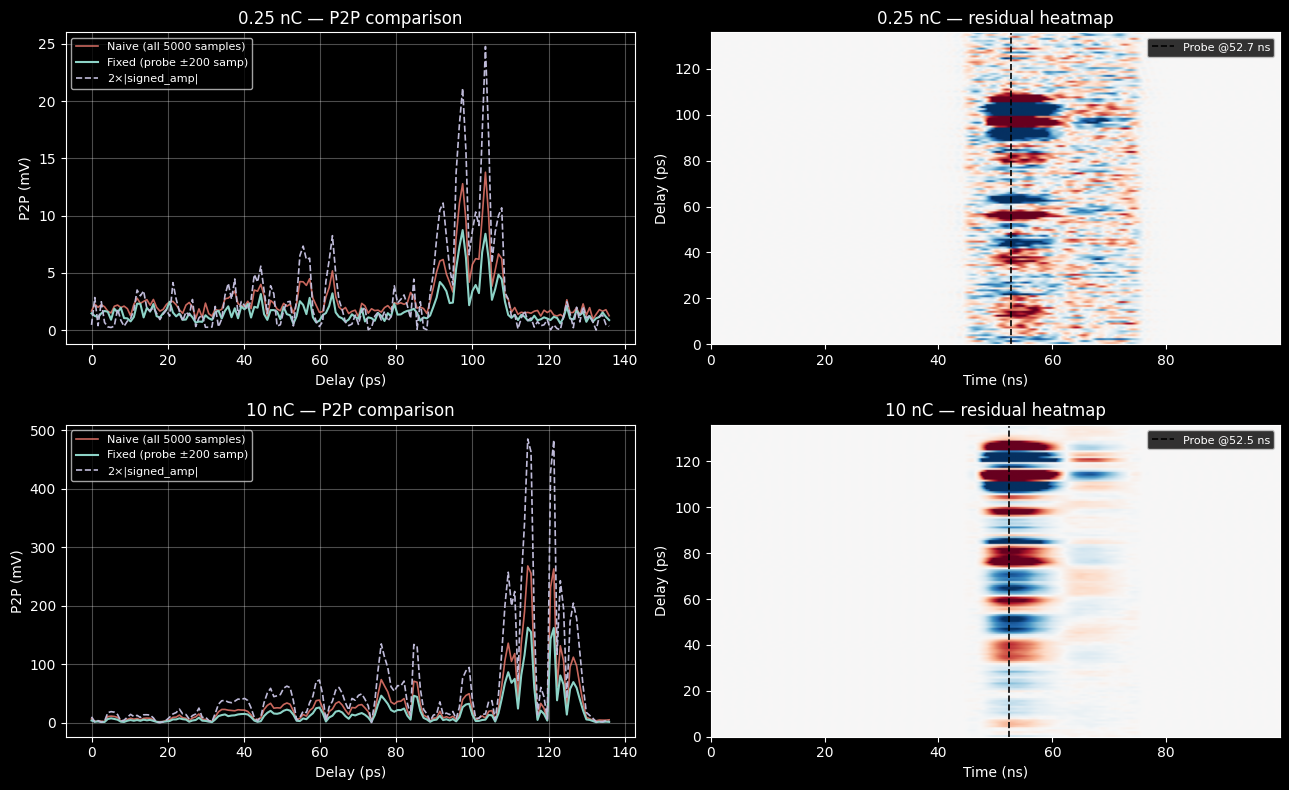

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax_row, scan_idx in zip(axes, [0, 6]):  # 0.25 nC and 10 nC
    d   = all_data[scan_idx]
    res = d['res']; dp=d['delay_ps']; sig=d['sig']; tp=d['tp']

    # Naive P2P across all 5000 samples
    p2p_naive = mV*(res.max(axis=1) - res.min(axis=1))

    # Fixed P2P: local window around probe pulse
    half_local = 200
    win_l = slice(max(0,tp-half_local), min(res.shape[1],tp+half_local))
    p2p_local = mV*(res[:,win_l].max(axis=1) - res[:,win_l].min(axis=1))

    # Reference: 2×|signed_amplitude|
    p2p_sig = 2*mV*np.abs(sig)

    ax_row[0].plot(dp, p2p_naive, 'C3',  lw=1.2, alpha=0.8, label='Naive (all 5000 samples)')
    ax_row[0].plot(dp, p2p_local, 'C0',  lw=1.5, label=f'Fixed (probe ±{half_local} samp)')
    ax_row[0].plot(dp, p2p_sig,   'C2--',lw=1.2, label='2×|signed_amp|')
    ax_row[0].set_xlabel('Delay (ps)'); ax_row[0].set_ylabel('P2P (mV)')
    ax_row[0].set_title(f'{d["label"]} — P2P comparison'); ax_row[0].legend(fontsize=8); ax_row[0].grid(True,alpha=0.3)

    # Residual heatmap to show where noise comes from
    t_ns = d['t_ns']
    vmax = np.percentile(np.abs(mV*res),98)
    ax_row[1].imshow(mV*res, aspect='auto',
                     extent=[t_ns[0],t_ns[-1],dp[0],dp[-1]],
                     origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax_row[1].axvline(t_ns[tp],color='k',ls='--',lw=1.2,label=f'Probe @{t_ns[tp]:.1f} ns')
    ax_row[1].set_xlabel('Time (ns)'); ax_row[1].set_ylabel('Delay (ps)')
    ax_row[1].set_title(f'{d["label"]} — residual heatmap'); ax_row[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('Results/P2P_bug_fix.png', dpi=200, bbox_inches='tight')
plt.show()

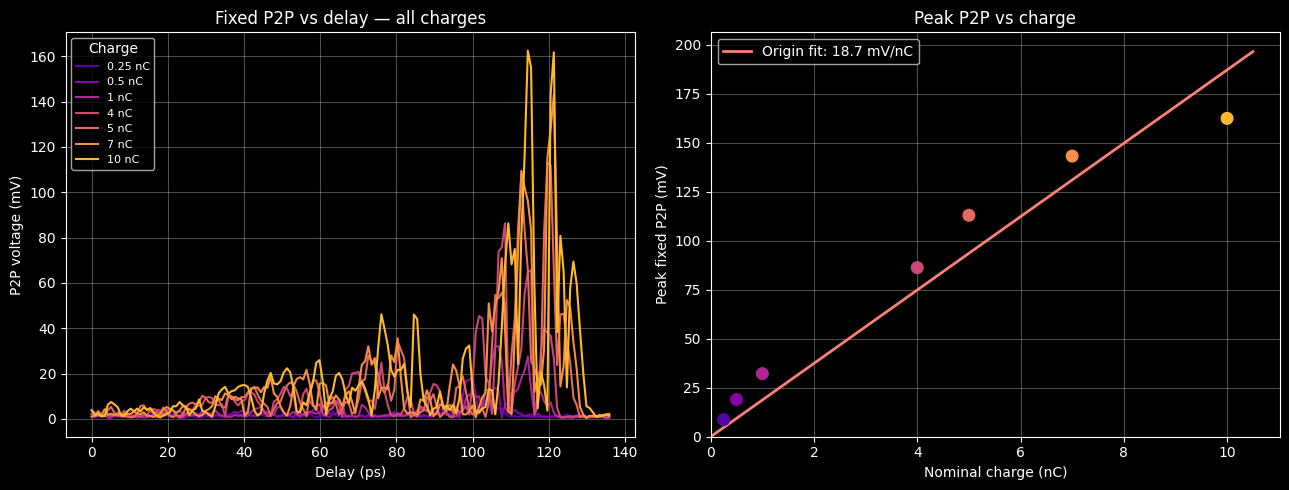

In [4]:
# ── P2P vs delay for all charges (fixed method) ───────────────────────────────
half_local = 200
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

Q_vals, peak_p2p = [], []
for d, col in zip(all_data, colors):
    res=d['res']; dp=d['delay_ps']; tp=d['tp']
    win_l=slice(max(0,tp-half_local),min(res.shape[1],tp+half_local))
    p2p=mV*(res[:,win_l].max(axis=1)-res[:,win_l].min(axis=1))
    ax1.plot(dp,p2p,color=col,lw=1.5,label=d['label'])
    Q_vals.append(d['Q']); peak_p2p.append(p2p.max())

ax1.set_xlabel('Delay (ps)'); ax1.set_ylabel('P2P voltage (mV)')
ax1.set_title('Fixed P2P vs delay — all charges')
ax1.legend(title='Charge',fontsize=8); ax1.grid(True,alpha=0.3)

Q_arr=np.array(Q_vals); pp_arr=np.array(peak_p2p)
slope=(Q_arr*pp_arr).sum()/(Q_arr**2).sum()
Q_fit=np.linspace(0,Q_arr.max()*1.05,200)
ax2.scatter(Q_arr,pp_arr,c=[colors[i] for i in range(len(Q_arr))],s=70,zorder=5)
ax2.plot(Q_fit,slope*Q_fit,'C3-',lw=2,label=f'Origin fit: {slope:.1f} mV/nC')
ax2.set_xlabel('Nominal charge (nC)'); ax2.set_ylabel('Peak fixed P2P (mV)')
ax2.set_title('Peak P2P vs charge'); ax2.legend(); ax2.grid(True,alpha=0.3)
ax2.set_xlim(left=0); ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/P2P_vs_delay_and_charge.png', dpi=200, bbox_inches='tight')
plt.show()

## Section 2: Voltage Integral vs Delay

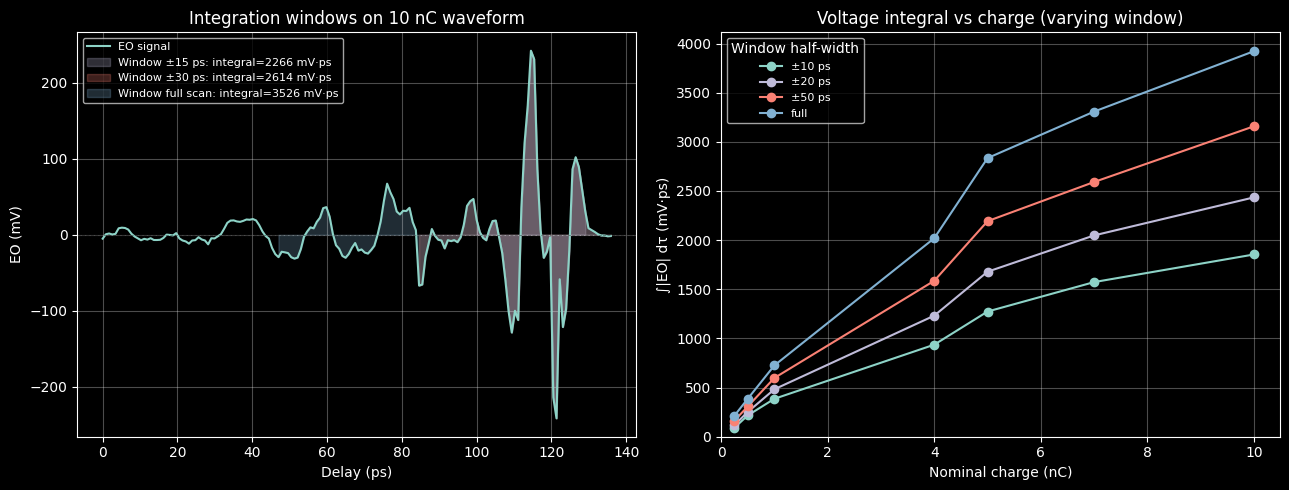

In [5]:
# ── Integration window illustration ──────────────────────────────────────────
d10 = all_data[-1]  # 10 nC
dp10, sig10 = d10['delay_ps'], d10['sig']
peak_idx    = np.argmax(np.abs(sig10))
peak_delay  = dp10[peak_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.plot(dp10, mV*sig10, 'C0', lw=1.5, label='EO signal')
for hw, col, lbl in [(15,'C2','±15 ps'),  (30,'C3','±30 ps'), (68,'C4','full scan')]:
    mask = np.abs(dp10 - peak_delay) <= hw
    integral_val = np.trapezoid(np.abs(sig10[mask]), dp10[mask]) * mV
    ax.fill_between(dp10, mV*sig10, where=mask, alpha=0.25, color=col,
                    label=f'Window {lbl}: integral={integral_val:.0f} mV·ps')
ax.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
ax.set_xlabel('Delay (ps)'); ax.set_ylabel('EO (mV)')
ax.set_title('Integration windows on 10 nC waveform'); ax.legend(fontsize=8); ax.grid(True,alpha=0.3)

# Integral vs charge for different windows
ax = axes[1]
for hw, col, lbl in [(10,'C0','±10 ps'), (20,'C2','±20 ps'), (50,'C3','±50 ps'), (None,'C4','full')]:
    integrals = []
    for d in all_data:
        dp_s, sig_s = d['delay_ps'], d['sig']
        if hw is None:
            mask = np.ones(len(dp_s), dtype=bool)
        else:
            pk_d = dp_s[np.argmax(np.abs(sig_s))]
            mask = np.abs(dp_s - pk_d) <= hw
        integrals.append(np.trapezoid(np.abs(sig_s[mask]), dp_s[mask]) * mV)
    ax.plot(Q_arr, integrals, 'o-', color=col, lw=1.5, ms=6, label=lbl)

ax.set_xlabel('Nominal charge (nC)'); ax.set_ylabel('∫|EO| dτ (mV·ps)')
ax.set_title('Voltage integral vs charge (varying window)')
ax.legend(title='Window half-width',fontsize=8); ax.grid(True,alpha=0.3)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/voltage_integral_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()

/tmp/ipykernel_105595/2598824585.py:13: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  signal_int = np.trapz(np.abs(sig_s[mask]), dp_s[mask])


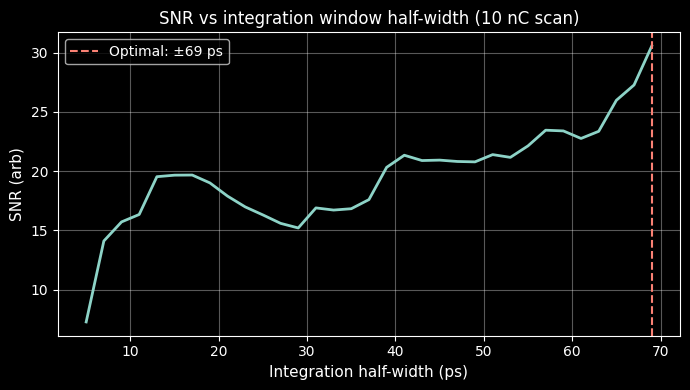

Optimal integration half-width: ±69 ps (SNR = 30.56)


In [6]:
# ── Optimal integration window via SNR ────────────────────────────────────────
half_widths = np.arange(5, 70, 2)  # ps
snr_vals    = []

for hw in half_widths:
    # SNR for 10 nC scan
    d = all_data[-1]; dp_s, sig_s = d['delay_ps'], d['sig']
    pk_d  = dp_s[np.argmax(np.abs(sig_s))]
    mask  = np.abs(dp_s - pk_d) <= hw
    nmask = ~mask
    if nmask.sum() < 5 or mask.sum() < 3:
        snr_vals.append(0); continue
    signal_int = np.trapz(np.abs(sig_s[mask]), dp_s[mask])
    noise_rms  = np.std(sig_s[nmask]) * np.sqrt(2*hw)  # noise × sqrt(window)
    snr_vals.append(signal_int / noise_rms if noise_rms > 0 else 0)

snr_arr = np.array(snr_vals)
opt_hw  = half_widths[snr_arr.argmax()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(half_widths, snr_arr, 'C0', lw=2)
ax.axvline(opt_hw, color='C3', ls='--', lw=1.5, label=f'Optimal: ±{opt_hw} ps')
ax.set_xlabel('Integration half-width (ps)', fontsize=11)
ax.set_ylabel('SNR (arb)', fontsize=11)
ax.set_title('SNR vs integration window half-width (10 nC scan)')
ax.legend(); ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('Results/integration_SNR_optimisation.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Optimal integration half-width: ±{opt_hw} ps (SNR = {snr_arr.max():.2f})')

## Section 3: ICT Metrics

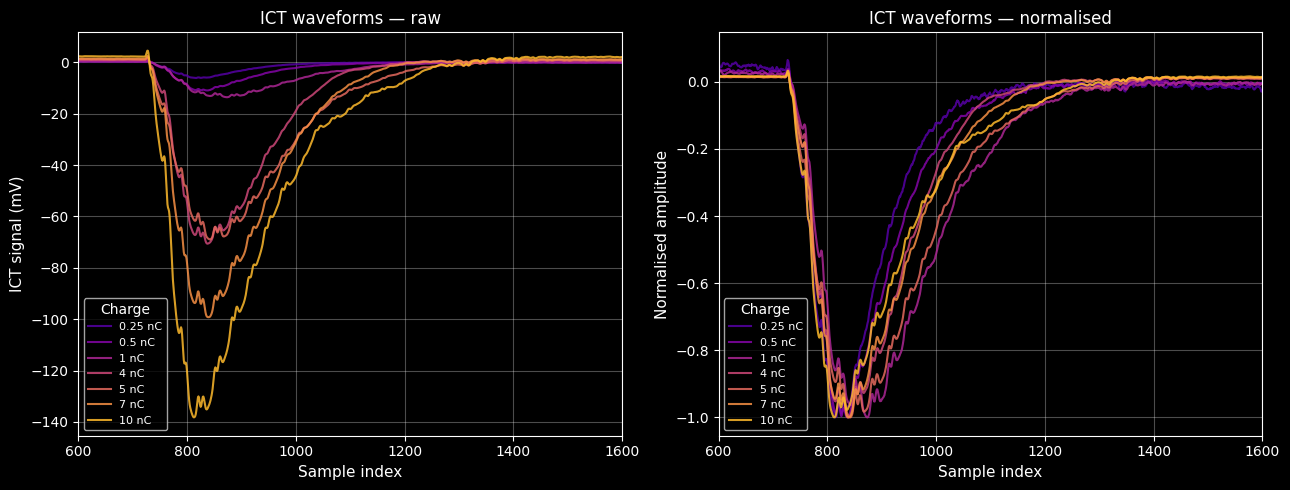

In [7]:
# ── ICT waveforms overlaid ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for d, col in zip(all_data, colors):
    ict = d['ict']  # (steps, 2502) baseline-corrected
    mean_wf = ict.mean(axis=0)
    t_ict   = np.arange(len(mean_wf))  # sample index
    axes[0].plot(t_ict, mean_wf*1e3, color=col, lw=1.5, alpha=0.85, label=d['label'])
    # Normalised
    norm = np.abs(mean_wf).max()
    axes[1].plot(t_ict, mean_wf/norm, color=col, lw=1.5, alpha=0.85, label=d['label'])

for ax, title, ylab in zip(axes, ['ICT waveforms — raw', 'ICT waveforms — normalised'],
                            ['ICT signal (mV)', 'Normalised amplitude']):
    ax.set_xlabel('Sample index', fontsize=11); ax.set_ylabel(ylab, fontsize=11)
    ax.set_title(title); ax.legend(title='Charge',fontsize=8); ax.grid(True,alpha=0.3)
    ax.set_xlim(600, 1600)

plt.tight_layout()
plt.savefig('Results/ICT_waveforms.png', dpi=200, bbox_inches='tight')
plt.show()

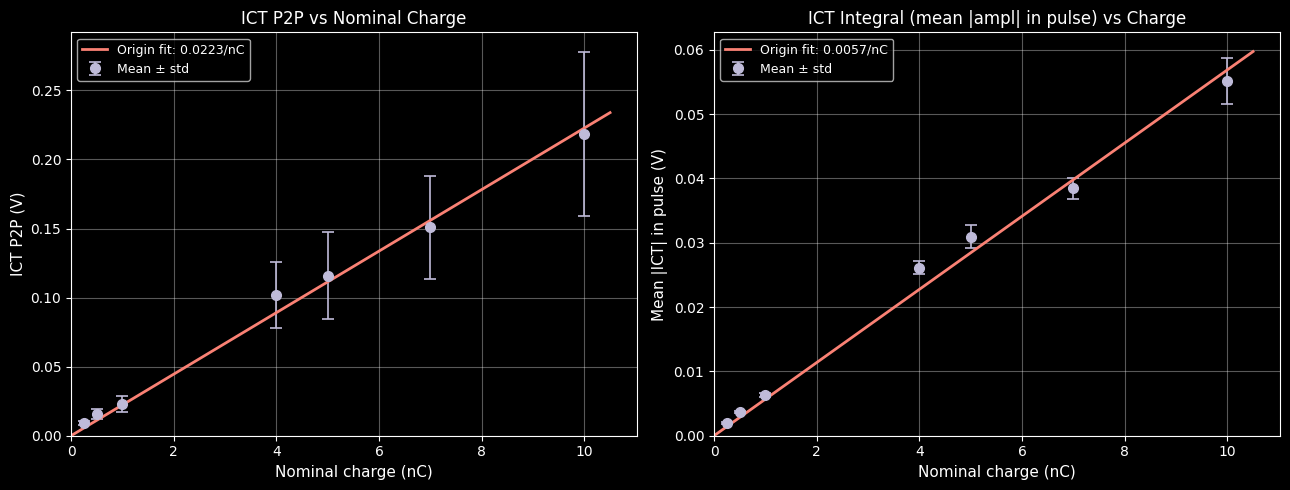

In [8]:
# ── ICT P2P and integral vs charge ────────────────────────────────────────────
ict_p2p_all, ict_p2p_std, ict_int_all, ict_int_std = [], [], [], []
pulse_win = slice(700, 1200)  # ICT pulse region

for d in all_data:
    ict = d['ict']  # (steps, 2502)
    # P2P per step
    p2p = (ict[:,pulse_win].max(axis=1) - ict[:,pulse_win].min(axis=1))
    ict_p2p_all.append(p2p.mean()); ict_p2p_std.append(p2p.std())
    # Integral per step: ∫ |ICT| dt within pulse window
    intg = np.abs(ict[:,pulse_win]).mean(axis=1)  # mean |amplitude|
    ict_int_all.append(intg.mean()); ict_int_std.append(intg.std())

Q_arr = np.array([d['Q'] for d in all_data])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, vals, stds, title, ylabel in zip(
    axes,
    [ict_p2p_all, ict_int_all],
    [ict_p2p_std, ict_int_std],
    ['ICT P2P vs Nominal Charge', 'ICT Integral (mean |ampl| in pulse) vs Charge'],
    ['ICT P2P (V)', 'Mean |ICT| in pulse (V)']):

    vals_a = np.array(vals); stds_a = np.array(stds)
    ax.errorbar(Q_arr, vals_a, yerr=stds_a, fmt='C2o', capsize=4, markersize=7,
                capthick=1.2, elinewidth=1.2, label='Mean ± std')
    slope = (Q_arr*vals_a).sum()/(Q_arr**2).sum()
    Q_fit = np.linspace(0,Q_arr.max()*1.05,200)
    ax.plot(Q_fit, slope*Q_fit, 'C3-', lw=2, label=f'Origin fit: {slope:.4f}/nC')
    ax.set_xlabel('Nominal charge (nC)',fontsize=11); ax.set_ylabel(ylabel,fontsize=11)
    ax.set_title(title); ax.legend(fontsize=9); ax.grid(True,alpha=0.35)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/ICT_P2P_and_integral.png', dpi=200, bbox_inches='tight')
plt.show()

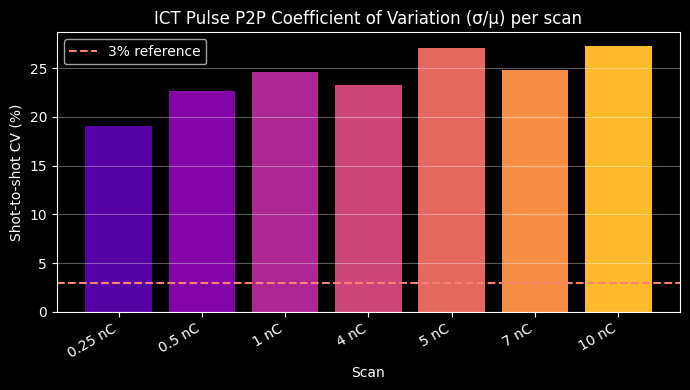

ICT shot-to-shot CV:
   0.25 nC: 19.1%
    0.5 nC: 22.7%
      1 nC: 24.6%
      4 nC: 23.3%
      5 nC: 27.0%
      7 nC: 24.8%
     10 nC: 27.3%


In [9]:
# ── ICT shot-to-shot stability ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))
cv_vals = [std/mean*100 if mean > 0 else 0
           for mean, std in zip(ict_p2p_all, ict_p2p_std)]
ax.bar(range(len(Q_arr)), cv_vals, color=colors)
ax.set_xticks(range(len(Q_arr)))
ax.set_xticklabels([d['label'] for d in all_data], rotation=30, ha='right')
ax.set_ylabel('Shot-to-shot CV (%)'); ax.set_xlabel('Scan')
ax.set_title('ICT Pulse P2P Coefficient of Variation (σ/μ) per scan')
ax.grid(True, alpha=0.35, axis='y')
ax.axhline(3, color='C3', ls='--', lw=1.5, label='3% reference')
ax.legend()
plt.tight_layout()
plt.savefig('Results/ICT_stability.png', dpi=200, bbox_inches='tight')
plt.show()
print('ICT shot-to-shot CV:')
for d, cv in zip(all_data, cv_vals):
    print(f"  {d['label']:>8}: {cv:.1f}%")

## Section 4: Noise Floor Characterisation

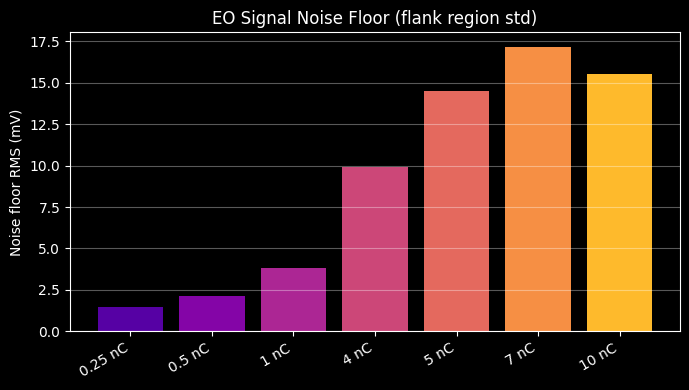

 0.25 nC: noise=1.45 mV  peak=12.4 mV  SNR=8.5
  0.5 nC: noise=2.12 mV  peak=25.3 mV  SNR=12.0
    1 nC: noise=3.81 mV  peak=45.1 mV  SNR=11.8
    4 nC: noise=9.90 mV  peak=128.4 mV  SNR=13.0
    5 nC: noise=14.53 mV  peak=167.5 mV  SNR=11.5
    7 nC: noise=17.18 mV  peak=206.3 mV  SNR=12.0
   10 nC: noise=15.53 mV  peak=242.4 mV  SNR=15.6


In [10]:
noise_floors = []
for d in all_data:
    dp_s, sig_s = d['delay_ps'], d['sig']
    # Flank regions (before and after signal)
    pk_d  = dp_s[np.argmax(np.abs(sig_s))]
    flank = np.abs(dp_s - pk_d) > 40  # >40 ps from peak
    if flank.sum() > 5:
        noise_floors.append(mV*np.std(sig_s[flank]))
    else:
        noise_floors.append(np.nan)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(Q_arr)), noise_floors, color=colors)
ax.set_xticks(range(len(Q_arr)))
ax.set_xticklabels([d['label'] for d in all_data], rotation=30, ha='right')
ax.set_ylabel('Noise floor RMS (mV)')
ax.set_title('EO Signal Noise Floor (flank region std)')
ax.grid(True, alpha=0.35, axis='y')
plt.tight_layout()
plt.savefig('Results/noise_floor.png', dpi=200, bbox_inches='tight')
plt.show()
for d, nf in zip(all_data, noise_floors):
    pk = mV*np.abs(d['sig']).max()
    snr = pk/nf if not np.isnan(nf) and nf > 0 else float('nan')
    print(f"{d['label']:>8}: noise={nf:.2f} mV  peak={pk:.1f} mV  SNR={snr:.1f}")

In [11]:
# ── Summary table ──────────────────────────────────────────────────────────────
print('=' * 100)
print(f"{'Label':>8} | {'Q_nom':>5} | {'Peak sig':>8} | {'Peak P2P':>8} | {'∫|EO| full':>10} | "
      f"{'ICT P2P':>8} | {'ICT CV':>7} | {'Noise':>7}")
print('-' * 100)
for i, d in enumerate(all_data):
    sig_s = d['sig']; res=d['res']; dp_s=d['delay_ps']; tp=d['tp']
    win_l=slice(max(0,tp-200),min(res.shape[1],tp+200))
    peak_sig = mV*np.abs(sig_s).max()
    peak_p2p = mV*(res[:,win_l].max(axis=1)-res[:,win_l].min(axis=1)).max()
    integral = np.trapz(np.abs(sig_s), dp_s)*mV
    ict_p2p_v = ict_p2p_all[i]*1e3  # mV
    cv_v = cv_vals[i]
    nf   = noise_floors[i]
    print(f"{d['label']:>8} | {d['Q']:5.2f} | {peak_sig:7.1f} mV | {peak_p2p:7.1f} mV | "
          f"{integral:9.0f}   | {ict_p2p_v:7.1f} mV | {cv_v:6.1f}% | {nf:6.2f} mV")
print('=' * 100)

   Label | Q_nom | Peak sig | Peak P2P | ∫|EO| full |  ICT P2P |  ICT CV |   Noise
----------------------------------------------------------------------------------------------------
 0.25 nC |  0.25 |    12.4 mV |     8.7 mV |       214   |     9.2 mV |   19.1% |   1.45 mV
  0.5 nC |  0.50 |    25.3 mV |    19.0 mV |       386   |    15.8 mV |   22.7% |   2.12 mV
    1 nC |  1.00 |    45.1 mV |    32.2 mV |       725   |    23.0 mV |   24.6% |   3.81 mV
    4 nC |  4.00 |   128.4 mV |    86.3 mV |      2019   |   102.1 mV |   23.3% |   9.90 mV
    5 nC |  5.00 |   167.5 mV |   113.0 mV |      2834   |   115.9 mV |   27.0% |  14.53 mV
    7 nC |  7.00 |   206.3 mV |   143.2 mV |      3308   |   150.9 mV |   24.8% |  17.18 mV
   10 nC | 10.00 |   242.4 mV |   162.4 mV |      3922   |   218.5 mV |   27.3% |  15.53 mV


/tmp/ipykernel_105595/895918716.py:11: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(np.abs(sig_s), dp_s)*mV


## Section 5: Log-Log Power Law Fits — BPD Metrics vs Charge

Fits $y = A \cdot Q^{\alpha}$ in log-log space for each of the three BPD voltage metrics.

- **Magnitude** — peak $|$signed amplitude$|$ from the probe-window estimator
- **P2P** — peak fixed P2P from the local window (±200 samples) around the probe
- **Integral** — $\int |$EO$|\ d\tau$ over the full scan

A slope $\alpha = 1$ means a linear (fully coherent) response; $\alpha < 1$ indicates saturation or partial coherence loss at high charge.

In [ ]:
# ── BPD metrics vs charge: log-log with power-law fit ─────────────────────────
half_local = 200

Q_arr_ll     = np.array([d['Q'] for d in all_data])
peak_sig_mV  = np.zeros(len(all_data))
peak_p2p_mV  = np.zeros(len(all_data))
integral_mVps = np.zeros(len(all_data))

for i, d in enumerate(all_data):
    sig_s = d['sig']; res = d['res']; dp_s = d['delay_ps']; tp = d['tp']
    peak_sig_mV[i]   = mV * np.abs(sig_s).max()
    win_l = slice(max(0, tp - half_local), min(res.shape[1], tp + half_local))
    peak_p2p_mV[i]   = mV * (res[:, win_l].max(axis=1) - res[:, win_l].min(axis=1)).max()
    integral_mVps[i] = np.trapezoid(np.abs(sig_s), dp_s) * mV

def power_law_fit_ll(Q, y):
    """Fit y = A * Q^alpha in log-log space; return (alpha, A)."""
    alpha, logA = np.polyfit(np.log10(Q), np.log10(y), 1)
    return alpha, 10**logA

metrics_ll = [
    (peak_p2p_mV,   'Peak P2P voltage (mV)',   'P2P'),
    (peak_sig_mV,   'Peak |amplitude| (mV)',    'Magnitude'),
    (integral_mVps, r'$\int|$EO$|\ d\tau$ (mV·ps)', 'Integral'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
Q_fit_ll = np.geomspace(Q_arr_ll.min() * 0.8, Q_arr_ll.max() * 1.25, 300)

print(f"{'Metric':12}  {'alpha':>6}  {'A':>8}  (y = A × Q^alpha)")
for ax, (y_arr, ylabel, label) in zip(axes, metrics_ll):
    alpha, A = power_law_fit_ll(Q_arr_ll, y_arr)
    y_fit = A * Q_fit_ll**alpha

    ax.scatter(Q_arr_ll, y_arr,
               c=[colors[i] for i in range(len(Q_arr_ll))], s=70, zorder=5, label='Data')
    ax.plot(Q_fit_ll, y_fit, 'C3-', lw=2,
            label=fr'$Q^{{{alpha:.2f}}}$ fit  ($A={A:.2f}$)')

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('Nominal charge (nC)', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(f'Log–log: {label} vs charge', fontsize=11)
    ax.legend(fontsize=9); ax.grid(True, alpha=0.35, which='both')
    print(f"{label:12}  {alpha:6.3f}  {A:8.3f}")

print("  (alpha=1: linear/coherent, alpha<1: saturation at high charge)")

plt.tight_layout()
plt.savefig('Results/BPD_metrics_loglog_powerlaw.png', dpi=200, bbox_inches='tight')
plt.show()